# Clustering

### Why is clustering "unsupervised"?
There are **no labels**. The input is just raw data, and the model has to find hidden structure (groups) on its own.

### What makes a good clustering?
- Points **inside** one cluster share similar properties → **intra-cluster** distances should be **small**.
- Points in **different** clusters are different → **inter-cluster** distances should be **large**.

### Measuring "similar": distance functions
| Name | Formula |
|---|---|
| Euclidean ($L_2$) | $d = \sqrt{\sum_i (x_i - y_i)^2}$ |
| Manhattan ($L_1$) | $d = \sum_i \lvert x_i - y_i \rvert$ |
| Chebyshev ($L_\infty$) | $d = \max_i \lvert x_i - y_i \rvert$ |
| Minkowski ($L_p$) | $d = \big(\sum_i \lvert x_i - y_i \rvert^p\big)^{1/p}$ ($p=1$ Manhattan, $p=2$ Euclidean, $p\to\infty$ Chebyshev) |
| Cosine | $d = 1 - \dfrac{x \cdot y}{\lVert x \rVert \lVert y \rVert}$ |

### Hard vs soft clustering
- **Hard:** every point gets exactly **one** cluster. Point A → $C_1$
- **Soft:** every point gets a **probability** for each cluster:

| Point | $C_1$ | $C_2$ |
|---|---|---|
| A | 0.8 | 0.2 |

### Algorithms in this notebook
| Algorithm | Type | Idea | You choose |
|---|---|---|---|
| **KMeans** | Hard | centroid-based: each point joins its nearest centre | `k` |
| **Hierarchical** | Hard | connectivity-based: repeatedly merge (or split) clusters | `n_clusters` or `distance_threshold`, and the linkage |
| **DBSCAN** | Hard | density-based: clusters are dense regions, the rest is noise | `eps`, `min_samples` |
| **GMM** | Soft | model-based: data comes from a mix of Gaussians | number of Gaussians, covariance type |
| *PCA* (not a clustering method) | Dimensionality reduction | rotates the data onto the directions of greatest variance | number of components |

## 1. Setup and toy datasets
Every algorithm is tried on the **same three small 2D datasets**, so we can see where each one shines and where it fails:
- **blobs**: 3 round, well-separated groups plus 5 outliers
- **moons**: 2 curved, interleaving shapes
- **stretched**: 3 long, slanted groups lying close to each other

Clustering uses distances, so every dataset is **standardised** (mean 0, standard deviation 1 per feature).

We also know the true groups (`y_true`). A real clustering problem would not have them; here we use them only to check results.

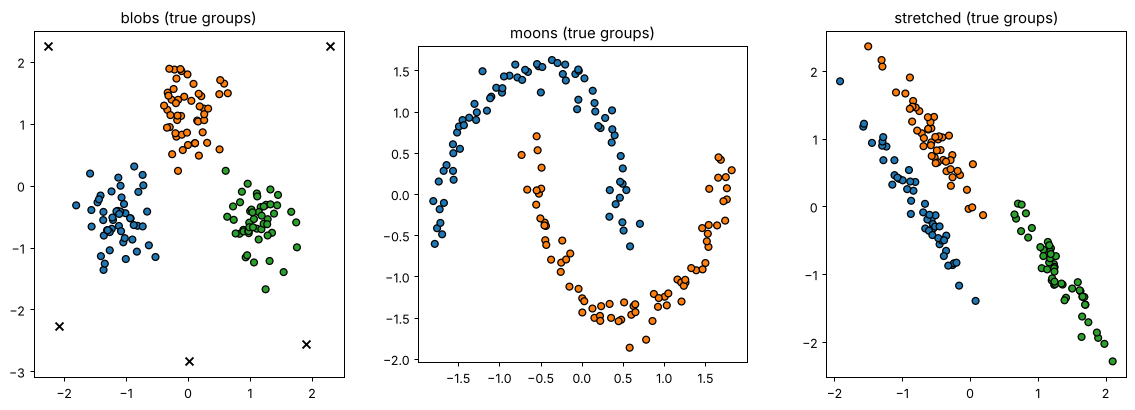

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons, load_digits
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, BisectingKMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

def standardise(X):
    return (X - X.mean(axis=0)) / X.std(axis=0)

X_b, y_b = make_blobs(n_samples=150, centers=[(-3, 0), (0, 3), (3, 0)], cluster_std=0.7, random_state=0)
outliers = np.array([[-6, 5], [6, 5], [0, -4], [5, -3.5], [-5.5, -3]])
X_b, y_b = np.vstack([X_b, outliers]), np.r_[y_b, [-1] * 5]     # true label -1 = outlier

X_m, y_m = make_moons(n_samples=150, noise=0.06, random_state=0)

X_s, y_s = make_blobs(n_samples=150, centers=3, random_state=170)
X_s = X_s @ np.array([[0.6, -0.6], [-0.4, 0.8]])                # stretch and tilt the blobs

data = {'blobs': (standardise(X_b), y_b),
        'moons': (standardise(X_m), y_m),
        'stretched': (standardise(X_s), y_s)}


def show(X, labels, title='', ax=None):
    # Colour points by cluster; label -1 (noise) is drawn as a black x
    ax = ax or plt.gca()
    noise = labels == -1
    ax.scatter(X[~noise, 0], X[~noise, 1], c=labels[~noise] % 10, cmap='tab10', vmin=0, vmax=9, s=30, edgecolor='k')
    ax.scatter(X[noise, 0], X[noise, 1], c='k', marker='x', s=40)
    ax.set_title(title)
    ax.set_aspect('equal')


fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, (X, y_true)) in zip(axes, data.items()):
    show(X, y_true, f'{name} (true groups)', ax=ax)
plt.show()

## 2. How do we judge a clustering?
There are no labels, so there is no "accuracy". Instead we use two kinds of metrics.

### Internal metrics: use only the data and the clusters
Notation: clusters $C_1, \dots, C_k$ with centroids $\mu_1, \dots, \mu_k$, overall mean $\bar{x}$, $n$ points.

| Metric | Formula | What it measures | Better |
|---|---|---|---|
| **WCSS** (Within-Cluster Sum of Squares), called **inertia** in scikit-learn | $\displaystyle\sum_{j=1}^{k} \sum_{x \in C_j} \lVert x - \mu_j \rVert^2$ | how **tight** the clusters are | lower |
| **BCSS** (Between-Cluster Sum of Squares) | $\displaystyle\sum_{j=1}^{k} \lvert C_j \rvert \, \lVert \mu_j - \bar{x} \rVert^2$ | how **far apart** the clusters are | higher |
| **Silhouette** | per point: $s = \dfrac{b - a}{\max(a, b)}$, score = average over all points | $a$ = mean distance to the other points of **its own** cluster, $b$ = mean distance to the points of the **nearest other** cluster. $s \approx 1$: deep inside its cluster, $s \approx 0$: on a border, $s < 0$: probably in the wrong cluster | higher (max 1) |

Note: $\text{WCSS} + \text{BCSS} = \text{TSS}$ (total sum of squares), which is fixed for a dataset. Making clusters tighter automatically makes them more separated.

In [2]:
def evaluate(X, labels, y_true):
    keep = labels != -1                                  # internal metrics ignore DBSCAN noise
    Xk, lk = X[keep], labels[keep]
    clusters = np.unique(lk)
    wcss = sum(((Xk[lk == c] - Xk[lk == c].mean(axis=0)) ** 2).sum() for c in clusters)

    print(f"Clusters found:    {len(clusters)}   (noise points: {np.sum(~keep)})")
    print(f"WCSS / inertia:    {wcss:.2f}   (lower = tighter)")
    if len(clusters) >= 2:
        print(f"Silhouette:        {silhouette_score(Xk, lk):.3f}   (higher is better, max 1)")
        print(f"Davies-Bouldin:    {davies_bouldin_score(Xk, lk):.3f}   (lower is better, min 0)")
        print(f"Calinski-Harabasz: {calinski_harabasz_score(Xk, lk):.1f}   (higher is better)")
    print(f"ARI vs true groups: {adjusted_rand_score(y_true, labels):.3f}   (1 = perfect, 0 = random)")


### Silhouette by hand
Let's compute the silhouette of one point ourselves, using the true groups of the `stretched` data as the "clustering".
Change `i` to pick another point. Points in the middle of a group score close to 1; points near another group score close to 0 or even below.

a = 0.531   b = 1.121   silhouette = (b - a) / max(a, b) = 0.526
scikit-learn's value for this point: 0.526


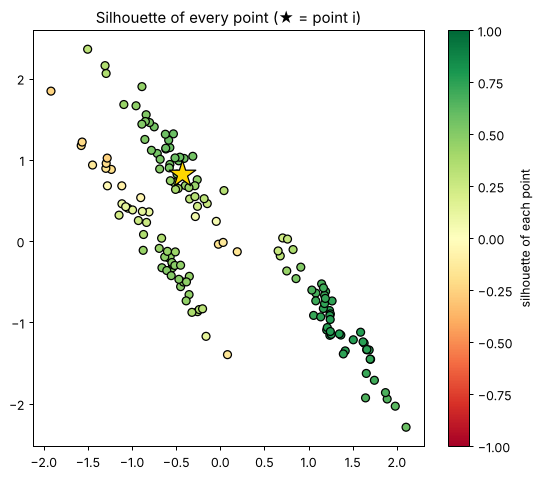

In [3]:
i = 0      # index of the point to inspect (0 to 149)

X, y_true = data['stretched']
dist = np.linalg.norm(X - X[i], axis=1)                      # distance from point i to every point

own = y_true == y_true[i]
a = dist[own].sum() / (own.sum() - 1)                        # mean distance to its own cluster (excluding itself)
b = min(dist[y_true == c].mean() for c in np.unique(y_true) if c != y_true[i])   # nearest other cluster
s = (b - a) / max(a, b)

print(f"a = {a:.3f}   b = {b:.3f}   silhouette = (b - a) / max(a, b) = {s:.3f}")
print(f"scikit-learn's value for this point: {silhouette_samples(X, y_true)[i]:.3f}")

plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], c=silhouette_samples(X, y_true), cmap='RdYlGn', vmin=-1, vmax=1, s=40, edgecolor='k')
plt.colorbar(label='silhouette of each point')
plt.scatter(X[i, 0], X[i, 1], c='gold', marker='*', s=500, edgecolor='k')
plt.title('Silhouette of every point (★ = point i)')
plt.show()

## 3. KMeans (hard clustering)

### Idea
Pick $k$ centres (**centroids**). Every point belongs to its nearest centroid. $k$ is a **hyperparameter**: we must choose it.

### What KMeans minimises
$$\min_{c_1, \dots, c_k,\ \pi} \ \sum_{i=1}^{n} \lVert x_i - c_{\pi(x_i)} \rVert^2 \qquad (= \text{WCSS})$$
where $c_j$ are the centroids and $\pi(x_i)$ is the cluster that point $x_i$ is assigned to.

### How: coordinate descent
"When there are many variables, optimise one group at a time while keeping the others fixed."
1. **Fix the centroids, choose the assignments:** the best cluster for each point is simply the nearest centroid:
$\pi(x_i) = \arg\min_{j} \lVert x_i - c_j \rVert^2$
2. **Fix the assignments, choose the centroids:** setting the derivative of $\sum_{x_i \in C_j} \lVert x_i - c_j \rVert^2$ to zero gives the **mean**:
$c_j = \dfrac{1}{\lvert C_j \rvert} \displaystyle\sum_{x_i \in C_j} x_i$

Each step can only **lower** WCSS, so the algorithm always stops. But the objective is **not convex**, so it can get stuck in a **local minimum** depending on where it starts.

*Note:* the mean is optimal only because we use (squared) Euclidean distance. With Manhattan distance the best centre is the **median** (**k-medians**); for categorical data it's the **mode** (**k-modes**).

### Algorithm
1. Choose $k$ random data points ("seeds") as the initial centroids.
2. Assign each point to the closest centroid.
3. Recompute each centroid as the mean of its points.
4. Repeat steps 2–3 until a stopping criterion is met.

**Stopping criteria:** centroids stop moving (used below) · no point changes cluster · WCSS decreases by less than a small threshold · a maximum number of iterations is reached.

### Better starting points: k-means++
1. Pick the first centroid at random.
2. Pick each next centroid with probability proportional to $D(x)^2$, the squared distance to the nearest centroid chosen so far. Far-away points are likely to be picked, so the centroids start **spread out**.

scikit-learn uses k-means++ by default and also runs the whole algorithm `n_init` times, keeping the result with the lowest WCSS.

In [4]:
def kmeans_scratch(X, k, init='random', seed=0, max_iter=50):
    rng = np.random.default_rng(seed)
    if init == 'random':
        centroids = X[rng.choice(len(X), k, replace=False)]          # k random data points
    else:                                                            # k-means++
        centroids = [X[rng.integers(len(X))]]
        for _ in range(k - 1):
            d2 = np.min([((X - c) ** 2).sum(axis=1) for c in centroids], axis=0)
            centroids.append(X[rng.choice(len(X), p=d2 / d2.sum())])
        centroids = np.array(centroids)

    history = []
    for _ in range(max_iter):
        distances = np.linalg.norm(X[:, None] - centroids[None], axis=2)   # every point to every centroid
        labels = distances.argmin(axis=1)                                   # step 2: nearest centroid
        history.append((centroids, labels))
        new = np.array([X[labels == j].mean(axis=0) if np.any(labels == j) else centroids[j] for j in range(k)])  # step 3: mean
        if np.allclose(new, centroids):                                     # stop: centroids no longer move
            break
        centroids = new
    return history

### Watch KMeans step by step
Change the settings and re-run:
- `step = 0, 1, 2, ...` watches the centroids move (arrows) and the WCSS fall at every iteration.
- `init = 'random'` with `seed = 5` gets stuck in a **local minimum**: one centroid covers two groups while the third group is split between the other two centroids. Compare its final WCSS with `seed = 0`.
- `init = 'kmeans++'` usually starts better. It can still be fooled (try `seed = 1`): it likes far-away points, and the **outliers** are far away!
- `dataset = 'moons'` or `'stretched'`: KMeans assumes **round** clusters and cuts these shapes wrongly.
- Try `k = 2, 4, 5`.

Iteration 0: WCSS = 289.74   <- shown
Iteration 1: WCSS = 73.82
Iteration 2: WCSS = 60.32
Iteration 3: WCSS = 60.27
Converged after 4 iterations



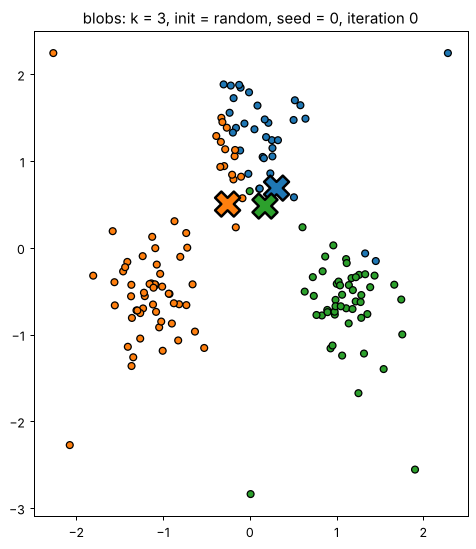

Clusters found:    3   (noise points: 0)
WCSS / inertia:    60.27   (lower = tighter)
Silhouette:        0.664   (higher is better, max 1)
Davies-Bouldin:    0.455   (lower is better, min 0)
Calinski-Harabasz: 314.9   (higher is better)
ARI vs true groups: 0.950   (1 = perfect, 0 = random)


In [5]:
dataset = 'blobs'     # 'blobs', 'moons', 'stretched'
k = 3
init = 'random'       # 'random' or 'kmeans++'
seed = 0              # different seed = different starting centroids
step = 0              # 0 = starting centroids; increase to watch the algorithm

X, y_true = data[dataset]
history = kmeans_scratch(X, k, init, seed)
step = min(step, len(history) - 1)
centroids, labels = history[step]

for i, (c, l) in enumerate(history):
    print(f"Iteration {i}: WCSS = {((X - c[l]) ** 2).sum():.2f}" + ("   <- shown" if i == step else ""))
print(f"Converged after {len(history)} iterations\n")

plt.figure(figsize=(7, 7))
show(X, labels, f'{dataset}: k = {k}, init = {init}, seed = {seed}, iteration {step}')
plt.scatter(centroids[:, 0], centroids[:, 1], c=np.arange(k) % 10, cmap='tab10', vmin=0, vmax=9,
            marker='X', s=400, edgecolor='k', linewidths=2)
if step > 0:
    for old, new in zip(history[step - 1][0], centroids):
        plt.annotate('', xy=new, xytext=old, arrowprops=dict(arrowstyle='->', lw=2))
plt.show()

evaluate(X, history[-1][1], y_true)    # metrics of the final clustering

### Choosing k
- **Elbow method:** plot WCSS against $k$. WCSS keeps falling, but after the right $k$ it falls much more slowly. Pick the $k$ at the "elbow".
- **Silhouette method:** plot the silhouette score against $k$ and pick the $k$ with the **highest** score.

Try all three datasets. The two methods may disagree, and on `moons` and `stretched` neither finds a good answer, because KMeans can't fit those shapes in the first place.

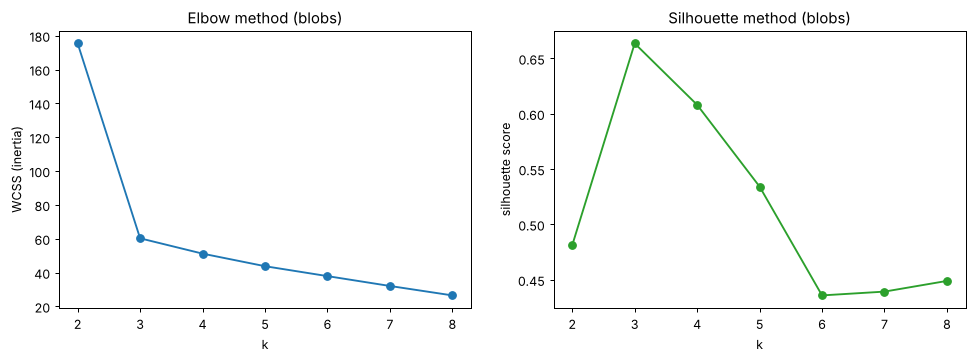

In [6]:
dataset = 'blobs'     # 'blobs', 'moons', 'stretched'

X, y_true = data[dataset]
ks = range(2, 9)
wcss_list, silhouette_list = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    wcss_list.append(km.inertia_)
    silhouette_list.append(silhouette_score(X, km.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(ks, wcss_list, 'o-')
ax1.set(title=f'Elbow method ({dataset})', xlabel='k', ylabel='WCSS (inertia)')
ax2.plot(ks, silhouette_list, 'o-', color='tab:green')
ax2.set(title=f'Silhouette method ({dataset})', xlabel='k', ylabel='silhouette score')
plt.show()

### Limitations of KMeans
- Works only where a **mean** is defined, so it doesn't work for categorical data (use k-modes).
- **k must be chosen** in advance.
- Assumes **round (spherical), convex** clusters of similar size.
- **Sensitive to initialisation** (local minima), so use k-means++ and several restarts.
- **Sensitive to outliers:** a far-away point pulls its centroid towards it.
- Different distance functions lead to different clusters, and the convergence criterion must be chosen carefully.

## 4. Hierarchical clustering (hard clustering)
Builds a **hierarchy** (tree) of clusters instead of one flat answer.
- **Agglomerative (bottom-up):** start with every point as its own cluster and **merge**.
- **Divisive (top-down):** start with one cluster containing everything and **split**.

### Agglomerative algorithm
1. Every data point starts as its own cluster.
2. Compute the distance (proximity) matrix between all clusters.
3. **Merge the two closest clusters.**
4. Update the distance matrix.
5. Repeat steps 3–4 until one cluster contains all points.

### Linkage: how far apart are two *clusters*?
For clusters $A$ and $B$:
| Linkage | Distance between A and B | Behaviour |
|---|---|---|
| **Single** | $\min_{a \in A, b \in B} d(a, b)$ (closest pair) | follows chains of points → any shape, but outliers stay separate and clusters can "leak" into each other |
| **Complete** | $\max_{a \in A, b \in B} d(a, b)$ (farthest pair) | compact clusters of similar diameter |
| **Average** | mean of all $d(a, b)$ | in between |
| **Ward** | increase in total WCSS caused by merging $A$ and $B$ | round clusters, very similar to KMeans |

### Dendrogram
A tree showing every merge. The **height** of each join is the distance at which the two clusters were merged. Points joined low down are very similar. **Cutting** the tree with a horizontal line gives the clusters.

**Hyperparameters:**
- `n_clusters`: stop merging (or splitting) when this many clusters are left.
- `distance_threshold`: keep merging only while the distance between clusters is below this value.

### Bottom-up by hand
8 named points. The code merges the closest pair of clusters at each step and prints it, so you can match every printed merge to a join in the dendrogram.

**Try `link = 'single'`, `'complete'`, `'average'`.** The merge order changes: with single linkage the chain A–B–C–D is joined at distance 1 and E, F join that chain next; with complete linkage the first merges are the same, but the next join happens at a much larger distance (about 2.9 instead of 1.4), so the chain grows far more slowly.

merge      E + F      at distance 0.57
merge      G + H      at distance 0.72
merge      A + B      at distance 1.00
merge     AB + C      at distance 1.00
merge    ABC + D      at distance 1.00
merge   ABCD + EF     at distance 1.43
merge ABCDEF + GH     at distance 2.65


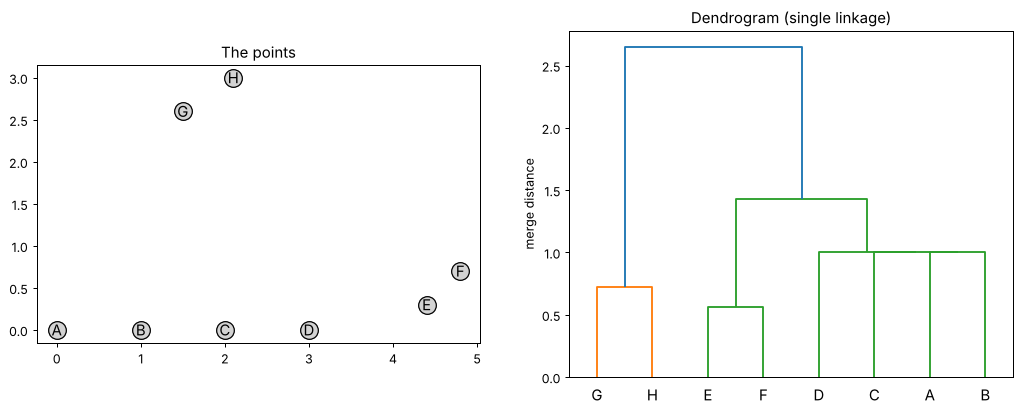

In [7]:
link = 'single'      # 'single', 'complete', 'average'

points = np.array([[0, 0], [1, 0], [2, 0], [3, 0], [4.4, 0.3], [4.8, 0.7], [1.5, 2.6], [2.1, 3.0]])
names = list('ABCDEFGH')

D = np.linalg.norm(points[:, None] - points[None], axis=2)     # distance between every pair of points
clusters = [[i] for i in range(len(points))]                   # step 1: every point is its own cluster

def cluster_distance(A, B):
    d = D[np.ix_(A, B)]                                        # all point-to-point distances between A and B
    return {'single': d.min(), 'complete': d.max(), 'average': d.mean()}[link]

while len(clusters) > 1:
    # step 3: find and merge the two closest clusters
    dist, i, j = min((cluster_distance(A, B), i, j)
                     for i, A in enumerate(clusters) for j, B in enumerate(clusters) if i < j)
    print(f"merge {''.join(names[p] for p in clusters[i]):>6} + {''.join(names[p] for p in clusters[j]):<6} at distance {dist:.2f}")
    clusters[i] = clusters[i] + clusters[j]
    del clusters[j]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.scatter(points[:, 0], points[:, 1], s=200, c='lightgray', edgecolor='k')
for name, (x, y) in zip(names, points):
    ax1.text(x, y, name, ha='center', va='center', fontsize=12)
ax1.set_title('The points')
ax1.set_aspect('equal')
dendrogram(linkage(points, method=link), labels=names, ax=ax2)
ax2.set(title=f'Dendrogram ({link} linkage)', ylabel='merge distance')
plt.show()

### Agglomerative clustering on our datasets
The red dashed line is where the tree is cut. Things to try:
- `moons` with `link = 'single'`: chaining follows the curves and gets them **perfectly**. Then try `'ward'`, which cuts the moons like KMeans does.
- `blobs` with `link = 'single'` and `n_clusters = 3`: two **outliers** become clusters of their own and all three real groups end up merged into one. Single linkage is very sensitive to outliers.
- `stretched` with each linkage.
- Set `distance_threshold` to a number (e.g. `1.0`) to cut at that height instead of using `n_clusters`.

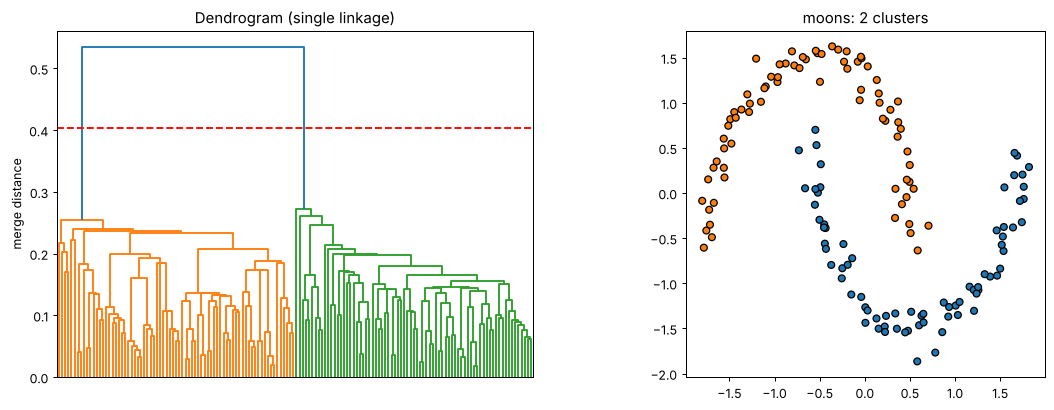

Clusters found:    2   (noise points: 0)
WCSS / inertia:    164.99   (lower = tighter)
Silhouette:        0.368   (higher is better, max 1)
Davies-Bouldin:    1.053   (lower is better, min 0)
Calinski-Harabasz: 121.1   (higher is better)
ARI vs true groups: 1.000   (1 = perfect, 0 = random)


In [8]:
dataset = 'moons'            # 'blobs', 'moons', 'stretched'
link = 'single'              # 'single', 'complete', 'average', 'ward'
n_clusters = 2               # must be at least 2
distance_threshold = None    # None, or a number: cut the tree at this height instead

X, y_true = data[dataset]
Z = linkage(X, method=link)                    # the full merge history (the tree)
if distance_threshold is None:
    labels = fcluster(Z, n_clusters, criterion='maxclust') - 1
    # The last n_clusters - 1 merges are undone, so the cut goes between the merge
    # that leaves n_clusters clusters (Z[-n_clusters]) and the one after it (Z[-(n_clusters-1)])
    cut = (Z[-n_clusters, 2] + Z[-(n_clusters - 1), 2]) / 2
else:
    labels = fcluster(Z, distance_threshold, criterion='distance') - 1
    cut = distance_threshold

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
dendrogram(Z, ax=ax1, no_labels=True, color_threshold=cut)
ax1.axhline(cut, color='r', linestyle='--')
ax1.set(title=f'Dendrogram ({link} linkage)', ylabel='merge distance')
show(X, labels, f'{dataset}: {len(np.unique(labels))} clusters', ax=ax2)
plt.show()

evaluate(X, labels, y_true)


### Divisive (top-down) clustering
Start with **one** cluster containing all points, then repeatedly **split** a cluster in two until there are `n_clusters`.

Trying every possible split is far too expensive, so a common practical version is **bisecting KMeans**:
1. Start with all points in one cluster.
2. Pick the "worst" cluster: the one with the largest WCSS (the most spread out).
3. Split it in two with KMeans (k = 2).
4. Repeat until there are `n_clusters` clusters.

Each panel below shows one more split. Try different datasets and `n_clusters`.

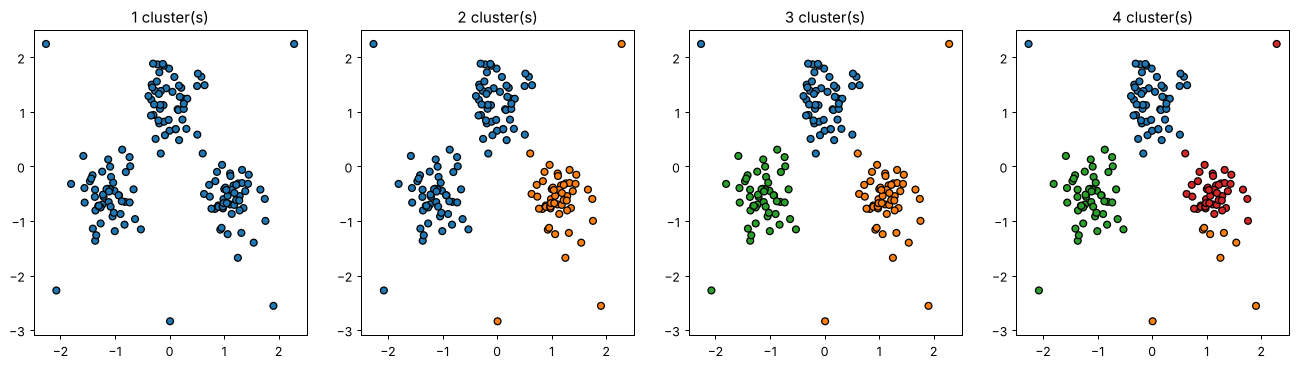

Clusters found:    4   (noise points: 0)
WCSS / inertia:    53.47   (lower = tighter)
Silhouette:        0.604   (higher is better, max 1)
Davies-Bouldin:    0.660   (lower is better, min 0)
Calinski-Harabasz: 241.5   (higher is better)
ARI vs true groups: 0.915   (1 = perfect, 0 = random)


In [9]:
def divisive(X, n_clusters):
    labels = np.zeros(len(X), dtype=int)                 # step 1: one big cluster
    history = [labels.copy()]
    for new in range(1, n_clusters):
        wcss = [((X[labels == c] - X[labels == c].mean(axis=0)) ** 2).sum() for c in range(new)]
        worst = np.argmax(wcss)                          # step 2: most spread-out cluster
        members = np.where(labels == worst)[0]
        halves = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X[members])   # step 3: split in two
        labels[members[halves == 1]] = new
        history.append(labels.copy())
    return history


dataset = 'blobs'     # 'blobs', 'moons', 'stretched'
n_clusters = 4

X, y_true = data[dataset]
history = divisive(X, n_clusters)

fig, axes = plt.subplots(1, n_clusters, figsize=(4.5 * n_clusters, 4.5), squeeze=False)
for i, labels in enumerate(history):
    show(X, labels, f'{i + 1} cluster(s)', ax=axes[0, i])
plt.show()

evaluate(X, history[-1], y_true)

### Agglomerative vs divisive
| | Agglomerative (bottom-up) | Divisive (top-down) |
|---|---|---|
| Pros | intuitive and the most common; works with any linkage; one run gives the whole tree, so every number of clusters is available | only needs $k-1$ splits when $k$ is small; the main structure is found first |
| Cons | sensitive to outliers (especially single linkage); needs $O(n^2)$ memory, so it is slow on large datasets | exact divisive clustering is very expensive; bisecting KMeans relies on KMeans, so it inherits local minima and randomness |

Once a merge or split is made it is **never undone**, so an early mistake stays in the final result.


## 5. DBSCAN (hard clustering)
**D**ensity-**B**ased **S**patial **C**lustering of **A**pplications with **N**oise.

Instead of distance to a centroid, DBSCAN looks at **density**: clusters are regions where points are tightly packed, separated by empty space. So it can find clusters of **any shape**, and it labels isolated points as **noise** (robust to outliers). We don't choose the number of clusters.

### Two hyperparameters
- `eps` ($\varepsilon$): radius of the neighbourhood around each point, $N_\varepsilon(p) = \{\, q : d(p, q) \le \varepsilon \,\}$
- `min_samples` (minPts): how many points the neighbourhood must contain for the point to be a **core** point (in scikit-learn this count includes the point itself)

### Three kinds of points
1. **Core point:** has at least `min_samples` points within `eps`.
2. **Border point:** not a core point, but within `eps` of a core point.
3. **Noise point:** neither; it belongs to no cluster (label −1).

### Algorithm
1. Identify all core points.
2. Take an unvisited core point and start a new cluster with it.
3. **Continue the chain:** add every point within `eps` of it. Neighbours that are themselves core points extend the cluster further. Only core points can extend a cluster; border points end it.
4. Repeat from step 2 until all core points are used. Whatever is left is noise.

### Effect of the hyperparameters
- `eps` ↑ (same `min_samples`): nearby clusters merge into one large cluster.
- `eps` ↓: clusters break into many small pieces and more points become noise.
- `min_samples` ↑ (same `eps`): more points become noise (outliers ↑).

### Point types up close
Shaded circles show the `eps`-neighbourhood of each **core** point. Try `eps = 0.3, 0.5, 1.0, 1.5` and `min_samples = 3, 5, 8`.

In [ ]:
eps = 0.5
min_samples = 5

rng = np.random.default_rng(3)
X_small = np.vstack([rng.normal([1, 1], 0.35, (9, 2)), rng.normal([3.5, 2], 0.35, (9, 2)),
                     [[2.2, 1.5], [0.2, 3.2], [4.5, 0.2]]])

db = DBSCAN(eps=eps, min_samples=min_samples).fit(X_small)
core = np.zeros(len(X_small), dtype=bool)
core[db.core_sample_indices_] = True
noise = db.labels_ == -1
border = ~core & ~noise

print(f"core: {core.sum()}   border: {border.sum()}   noise: {noise.sum()}   clusters: {len(np.unique(db.labels_[~noise]))}")

fig, ax = plt.subplots(figsize=(8, 7))
for p in X_small[core]:
    ax.add_patch(plt.Circle(p, eps, color='tab:green', alpha=0.08))
ax.scatter(X_small[core, 0], X_small[core, 1], s=150, c='tab:green', edgecolor='k', label='core')
ax.scatter(X_small[border, 0], X_small[border, 1], s=80, c='tab:orange', edgecolor='k', label='border')
ax.scatter(X_small[noise, 0], X_small[noise, 1], s=100, c='k', marker='x', label='noise')
for (x, y), label in zip(X_small, db.labels_):
    ax.text(x + 0.08, y + 0.08, label, fontsize=9)       # cluster number (-1 = noise)
ax.set_title(f'eps = {eps}, min_samples = {min_samples}')
ax.set_aspect('equal')
ax.legend()
plt.show()

### DBSCAN on our datasets
Big dots are core points, small dots are border points, black ✕ are noise. Things to try:
- `moons`: DBSCAN follows the curves. Then try `eps = 0.2` (too small: many fragments) and `eps = 1.0` (too big: one cluster).
- `blobs`: the 5 outliers are labelled as noise. DBSCAN may also mark a few points at the thin edges of clusters as noise.
- The **KMeans comparison** line printed below the evaluation is a useful warning. On `moons`, KMeans gets a *higher* silhouette than DBSCAN even though it cuts the moons wrongly, and its ARI is much lower. The silhouette rewards round, compact clusters, so **always look at the picture and at ARI as well**.


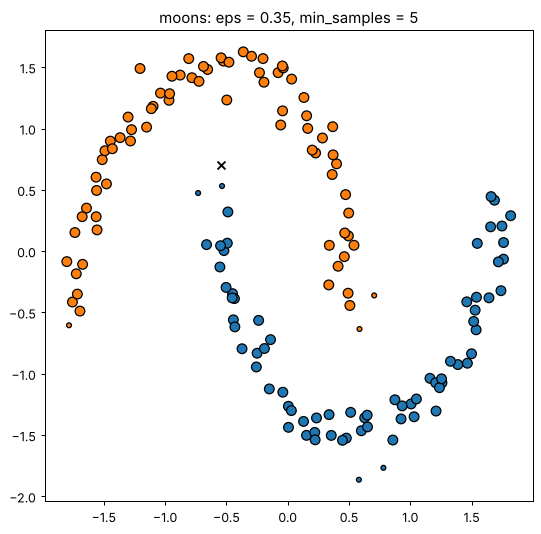

Clusters found:    2   (noise points: 1)
WCSS / inertia:    161.57   (lower = tighter)
Silhouette:        0.377   (higher is better, max 1)
Davies-Bouldin:    1.031   (lower is better, min 0)
Calinski-Harabasz: 125.2   (higher is better)
ARI vs true groups: 0.987   (1 = perfect, 0 = random)

For comparison, KMeans (k = 2) on moons: silhouette = 0.496, ARI = 0.441


In [10]:
dataset = 'moons'     # 'blobs', 'moons', 'stretched'
eps = 0.35
min_samples = 5

X, y_true = data[dataset]
db = DBSCAN(eps=eps, min_samples=min_samples).fit(X)
labels = db.labels_
core = np.zeros(len(X), dtype=bool)
core[db.core_sample_indices_] = True
noise = labels == -1

plt.figure(figsize=(7, 7))
plt.scatter(X[~noise, 0], X[~noise, 1], c=labels[~noise] % 10, cmap='tab10', vmin=0, vmax=9,
            s=np.where(core[~noise], 60, 15), edgecolor='k')
plt.scatter(X[noise, 0], X[noise, 1], c='k', marker='x', s=40)
plt.title(f'{dataset}: eps = {eps}, min_samples = {min_samples}')
plt.gca().set_aspect('equal')
plt.show()

evaluate(X, labels, y_true)

# Comparison: KMeans with k = 2 on the same data
km_labels = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X)
print(f"\nFor comparison, KMeans (k = 2) on {dataset}: silhouette = {silhouette_score(X, km_labels):.3f}, "
      f"ARI = {adjusted_rand_score(y_true, km_labels):.3f}")


### Choosing eps: the k-distance plot
For every point, find the distance to its `min_samples`-th nearest neighbour (counting itself, like DBSCAN does), then sort these distances.
Points inside clusters have small values; noise points have large ones. A good `eps` is where the curve bends sharply upwards ("knee").

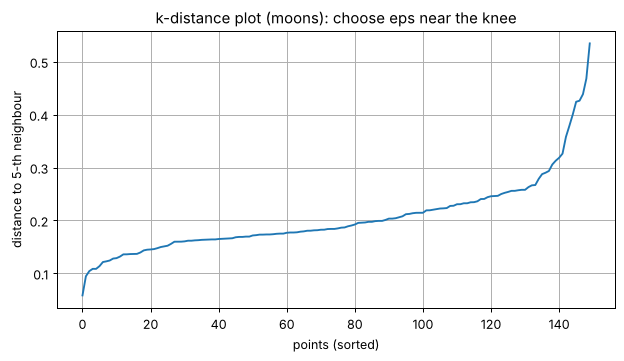

In [11]:
dataset = 'moons'     # 'blobs', 'moons', 'stretched'
min_samples = 5

X, y_true = data[dataset]
distances, _ = NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)   # first neighbour = the point itself
k_distance = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_distance)
plt.xlabel('points (sorted)')
plt.ylabel(f'distance to {min_samples}-th neighbour')
plt.title(f'k-distance plot ({dataset}): choose eps near the knee')
plt.grid(True)
plt.show()

### Limitations of DBSCAN
- Struggles when clusters have **different densities**: one `eps` can't fit both a dense and a sparse cluster.
- Results are **sensitive to `eps`**.
- In high dimensions distances become similar to each other, so choosing `eps` gets hard.
- Cannot assign a cluster to a brand-new point without re-running (there's no `predict`).

## 6. Gaussian Mixture Model, GMM (soft clustering)

### Idea
Assume every data point was **sampled from one of $k$ Gaussian (normal) distributions**, but we don't know which. Each Gaussian is a cluster with:
- mean $\mu_i$ (centre), variance $\sigma_i^2$ (spread; in 2D+ a covariance matrix $\Sigma_i$, i.e. an **ellipse**)
- weight $w_i$ (mixing coefficient: what fraction of the data it generates, $\sum_i w_i = 1$)

The probability density of the data is a **weighted sum of normal distributions**:
$$p(x) = w_1\, \mathcal{N}(x \mid \mu_1, \sigma_1^2) + \dots + w_k\, \mathcal{N}(x \mid \mu_k, \sigma_k^2)$$

To fit it we maximise the **log-likelihood**:
$$\ln p(X) = \sum_{n=1}^{N} \ln \sum_{i=1}^{k} \frac{w_i}{\sqrt{2\pi\sigma_i^2}}\, e^{-\frac{(x_n - \mu_i)^2}{2\sigma_i^2}}$$
Setting its derivatives to zero has **no closed-form solution** (the log of a sum is hard), so we use an iterative algorithm.

### Expectation–Maximisation (EM)
**Initialise** $\mu_i, \sigma_i^2, w_i$ (e.g. random means, wide variances, equal weights), then repeat:

**E-step (Expectation):** for every point, compute the probability that it came from each Gaussian, its **responsibility**:
$$\gamma_{ni} = P(G = i \mid x_n) = \frac{w_i\, \mathcal{N}(x_n \mid \mu_i, \sigma_i^2)}{\sum_{j=1}^{k} w_j\, \mathcal{N}(x_n \mid \mu_j, \sigma_j^2)}$$

**M-step (Maximisation):** update the parameters, using the responsibilities as "soft counts":
$$w_i = \frac{1}{N}\sum_{n=1}^{N} \gamma_{ni} \qquad \mu_i = \frac{\sum_n \gamma_{ni}\, x_n}{\sum_n \gamma_{ni}} \qquad \sigma_i^2 = \frac{\sum_n \gamma_{ni}\, (x_n - \mu_i)^2}{\sum_n \gamma_{ni}}$$

These are just a weighted fraction, a weighted mean and a weighted variance.

**Convergence criteria:** the log-likelihood barely changes · parameter changes fall below a threshold · a maximum number of iterations is reached.

**GMM vs KMeans:** KMeans is like a "hard" GMM where every cluster is a circle of the same size and each point belongs 100% to one cluster. GMM is the **soft** version and also learns the shape (ellipse) and size of each cluster.

### EM step by step in 1D
1D data from two overlapping bumps. Coloured curves are the weighted Gaussians $w_i \mathcal{N}(x \mid \mu_i, \sigma_i^2)$, the dashed curve is the full mixture $p(x)$, and each point at the bottom is coloured by its responsibilities (a **blend** of the cluster colours = soft membership).

Try `step = 0, 1, 2, 5, 10, ...`, a different `seed`, or `k = 3`. The log-likelihood **never decreases**.

In [12]:
def normal_pdf(x, mu, var):
    return np.exp(-(x - mu) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)

def gmm_1d(x, k, seed=0, max_iter=200, tol=0.01):
    rng = np.random.default_rng(seed)
    mu = rng.choice(x, k, replace=False)          # random data points as starting means
    var = np.full(k, x.var())                     # wide starting variances
    w = np.full(k, 1 / k)                         # equal starting weights
    history = []
    for _ in range(max_iter):
        # E-step: responsibilities gamma[n, i] = P(Gaussian i | x_n)
        weighted = w * normal_pdf(x[:, None], mu, var)
        loglik = np.log(weighted.sum(axis=1)).sum()
        gamma = weighted / weighted.sum(axis=1, keepdims=True)
        history.append((mu, var, w, gamma, loglik))
        if len(history) > 1 and loglik - history[-2][4] < tol:
            break
        # M-step: weighted fraction, weighted mean, weighted variance
        Nk = gamma.sum(axis=0)
        w = Nk / len(x)
        mu = (gamma * x[:, None]).sum(axis=0) / Nk
        var = (gamma * (x[:, None] - mu) ** 2).sum(axis=0) / Nk
    return history


rng = np.random.default_rng(1)
x_1d = np.concatenate([rng.normal(2, 0.8, 150), rng.normal(5, 1.2, 100)])

Converged after 22 iterations. Log-likelihood at each step:
[-581.1 -485.2 -483.7 -482.  -480.  -477.3 -473.9 -469.3 -463.8 -458.6
 -455.  -453.2 -452.7 -452.5 -452.4 -452.4 -452.3 -452.3 -452.3 -452.3
 -452.3 -452.3]

Step 0:
  Gaussian 0: weight w = 0.50   mean mu = 4.22   variance sigma^2 = 2.89
  Gaussian 1: weight w = 0.50   mean mu = 5.00   variance sigma^2 = 2.89

Soft assignments (rows = points, columns = P(Gaussian i | x)):
  x = 2.0: G0: 0.67   G1: 0.33
  x = 3.5: G0: 0.57   G1: 0.43
  x = 5.0: G0: 0.47   G1: 0.53


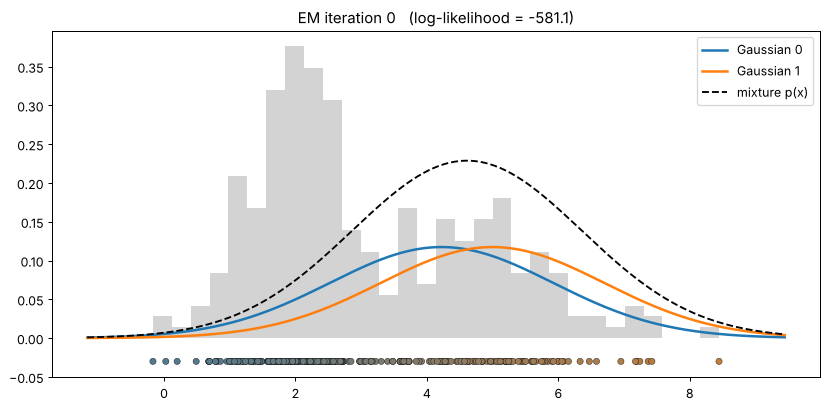

In [13]:
k = 2
seed = 0
step = 0      # 0 = starting guess; increase to watch EM

history = gmm_1d(x_1d, k, seed)
step = min(step, len(history) - 1)
mu, var, w, gamma, loglik = history[step]

print(f"Converged after {len(history)} iterations. Log-likelihood at each step:")
print(np.round([h[4] for h in history], 1))
print(f"\nStep {step}:")
for i in range(k):
    print(f"  Gaussian {i}: weight w = {w[i]:.2f}   mean mu = {mu[i]:.2f}   variance sigma^2 = {var[i]:.2f}")

examples = np.array([2.0, 3.5, 5.0])
resp = w * normal_pdf(examples[:, None], mu, var)
resp /= resp.sum(axis=1, keepdims=True)
print("\nSoft assignments (rows = points, columns = P(Gaussian i | x)):")
for x, r in zip(examples, resp):
    print(f"  x = {x}: " + "   ".join(f"G{i}: {p:.2f}" for i, p in enumerate(r)))

colors = plt.cm.tab10(np.arange(k) % 10)[:, :3]
grid = np.linspace(x_1d.min() - 1, x_1d.max() + 1, 400)
plt.figure(figsize=(11, 5))
plt.hist(x_1d, bins=30, density=True, color='lightgray')
for i in range(k):
    plt.plot(grid, w[i] * normal_pdf(grid, mu[i], var[i]), color=colors[i], lw=2, label=f'Gaussian {i}')
plt.plot(grid, sum(w[i] * normal_pdf(grid, mu[i], var[i]) for i in range(k)), 'k--', label='mixture p(x)')
plt.scatter(x_1d, np.full(len(x_1d), -0.03), c=gamma @ colors, s=25, edgecolor='k', linewidths=0.3)
plt.title(f'EM iteration {step}   (log-likelihood = {loglik:.1f})')
plt.legend()
plt.show()

### GMM in 2D with scikit-learn
In 2D each Gaussian has a **covariance matrix** $\Sigma_i$, so a cluster is an **ellipse** that can be stretched and tilted. `covariance_type` controls how flexible the ellipses are:

| `covariance_type` | Shape of each cluster |
|---|---|
| `'full'` | any ellipse, each cluster its own |
| `'tied'` | all clusters share the same ellipse shape |
| `'diag'` | ellipses aligned with the axes (no tilt) |
| `'spherical'` | circles (like KMeans, but still soft) |

Each point's colour is a **blend** of the cluster colours weighted by its probabilities, so points between clusters look mixed. Grey contour lines show the fitted density $p(x)$, and the 3 **least certain** points are circled and printed.

Things to try:
- `stretched` with `'full'`: GMM fits the tilted groups **perfectly** (KMeans couldn't). Then try `'spherical'` and watch it fail like KMeans.
- `moons`: Gaussians can't bend, so GMM fails here, just like KMeans.
- Change `n_components`.

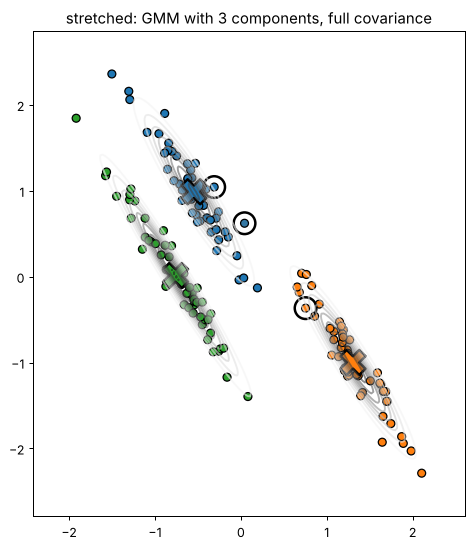

Least certain points (probability of each cluster):
  point 149: C0: 0.91   C1: 0.09   C2: 0.00
  point 16: C0: 1.00   C1: 0.00   C2: 0.00
  point 17: C0: 0.00   C1: 1.00   C2: 0.00

Log-likelihood: -170.9   AIC: 375.8   BIC: 426.9

Clusters found:    3   (noise points: 0)
WCSS / inertia:    71.74   (lower = tighter)
Silhouette:        0.446   (higher is better, max 1)
Davies-Bouldin:    0.948   (lower is better, min 0)
Calinski-Harabasz: 233.8   (higher is better)
ARI vs true groups: 1.000   (1 = perfect, 0 = random)


In [14]:
dataset = 'stretched'       # 'blobs', 'moons', 'stretched'
n_components = 3
covariance_type = 'full'    # 'full', 'tied', 'diag', 'spherical'

X, y_true = data[dataset]
gmm = GaussianMixture(n_components=n_components, covariance_type=covariance_type, random_state=0).fit(X)
probs = gmm.predict_proba(X)                 # soft assignment: one probability per cluster
labels = probs.argmax(axis=1)                # hard assignment: the most likely cluster

colors = plt.cm.tab10(np.arange(n_components) % 10)[:, :3]
xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 200),
                     np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 200))
density = np.exp(gmm.score_samples(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)   # p(x)
uncertain = np.argsort(probs.max(axis=1))[:3]

plt.figure(figsize=(8, 7))
plt.contour(xx, yy, density, levels=10, cmap='Greys', alpha=0.6)
plt.scatter(X[:, 0], X[:, 1], c=probs @ colors, s=40, edgecolor='k')
plt.scatter(gmm.means_[:, 0], gmm.means_[:, 1], c=colors, marker='X', s=400, edgecolor='k', linewidths=2)
plt.scatter(X[uncertain, 0], X[uncertain, 1], s=300, facecolors='none', edgecolors='k', linewidths=2)
plt.title(f'{dataset}: GMM with {n_components} components, {covariance_type} covariance')
plt.gca().set_aspect('equal')
plt.show()

print("Least certain points (probability of each cluster):")
for i in uncertain:
    print(f"  point {i}: " + "   ".join(f"C{c}: {p:.2f}" for c, p in enumerate(probs[i])))
print(f"\nLog-likelihood: {gmm.score(X) * len(X):.1f}   AIC: {gmm.aic(X):.1f}   BIC: {gmm.bic(X):.1f}\n")
evaluate(X, labels, y_true)

### GMM-specific metrics and choosing the number of Gaussians
- **Log-likelihood** $\ln L$: how probable the data is under the model (higher is better). It **always increases** with more components, so like WCSS it can't choose $k$ on its own.
- **AIC** $= 2p - 2\ln L$ and **BIC** $= p \ln N - 2\ln L$, where $p$ = number of model parameters and $N$ = number of points. Both reward a good fit but **penalise extra parameters**; BIC penalises them more. **Lower is better**: pick the number of components at the minimum.

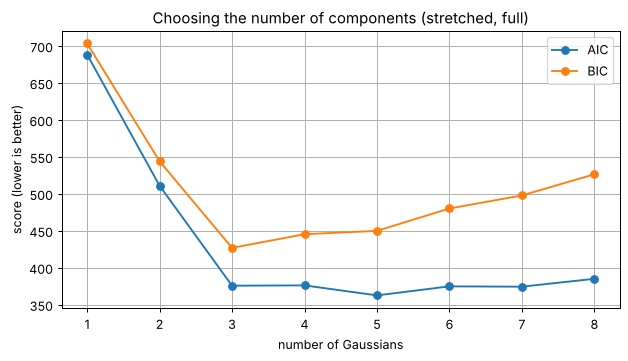

In [15]:
dataset = 'stretched'       # 'blobs', 'moons', 'stretched'
covariance_type = 'full'    # 'full', 'tied', 'diag', 'spherical'

X, y_true = data[dataset]
ns = range(1, 9)
models = [GaussianMixture(n_components=n, covariance_type=covariance_type, random_state=0).fit(X) for n in ns]

plt.figure(figsize=(8, 4))
plt.plot(ns, [m.aic(X) for m in models], 'o-', label='AIC')
plt.plot(ns, [m.bic(X) for m in models], 'o-', label='BIC')
plt.xlabel('number of Gaussians')
plt.ylabel('score (lower is better)')
plt.title(f'Choosing the number of components ({dataset}, {covariance_type})')
plt.legend()
plt.grid(True)
plt.show()

### Limitations of GMM
- Iterative, and **converges to a local optimum** that depends on the **initialisation** (try different `seed` values in the 1D demo).
- The number of components $k$ must be specified.
- Clusters can only be **ellipses**: it fails on curved shapes like `moons`.
- Sensitive to outliers. Overall its limitations are similar to KMeans, since it is like a soft version of KMeans.

## 7. Dimensionality reduction with PCA
**PCA** (Principal Component Analysis) is **not a clustering algorithm**. It is an unsupervised method that rewrites the data on new axes, the *principal components*, ordered by how much variance each one captures. In a clustering workflow it is useful for three things:
- **Visualisation:** project high-dimensional data to 2D so the clusters can be seen.
- **Noise reduction:** directions with very little variance are often noise, and dropping them can make clustering more stable.
- **Speed:** fewer features make KMeans and GMM faster, and in high dimensions distances become less informative.

### Idea
Find the unit-length direction $w_1$ along which the projected data has the **largest variance**:
$$w_1 = \arg\max_{\lVert w \rVert = 1} \operatorname{Var}(Xw)$$
The second component $w_2$ does the same, but must be **orthogonal** to $w_1$. The rest follow in the same way.

### How it is computed
1. **Centre** the data: subtract the mean of each feature.
2. Compute the **covariance matrix** $\Sigma = \frac{1}{n-1} X^\top X$.
3. Compute its **eigenvectors** $w_j$ and **eigenvalues** $\lambda_j$. The eigenvectors are the principal components, and $\lambda_j$ is the variance of the data along $w_j$.
4. **Sort** by $\lambda_j$ (largest first) and keep the first $m$ components. The reduced data is $Z = X W_m$, where $W_m$ holds those $m$ eigenvectors as columns.

The **explained variance ratio** of component $j$ is $\lambda_j / \sum_i \lambda_i$. In practice we keep the fewest components that reach a target, such as 90% of the total variance.

### Scale matters
PCA maximises variance, so a feature measured in large units would dominate. Standardise the data first, as we already do for all datasets in this notebook.

### PCA by hand
Below, PCA is computed from the four steps above and compared with scikit-learn's `PCA`. The arrows show the principal components, with length proportional to the spread of the data along them.


Eigenvalues (variance along each component): [1.839 0.174]
Explained variance ratio (scratch):      [0.914 0.086]
Explained variance ratio (scikit-learn): [0.914 0.086]
Same projection (up to sign): True


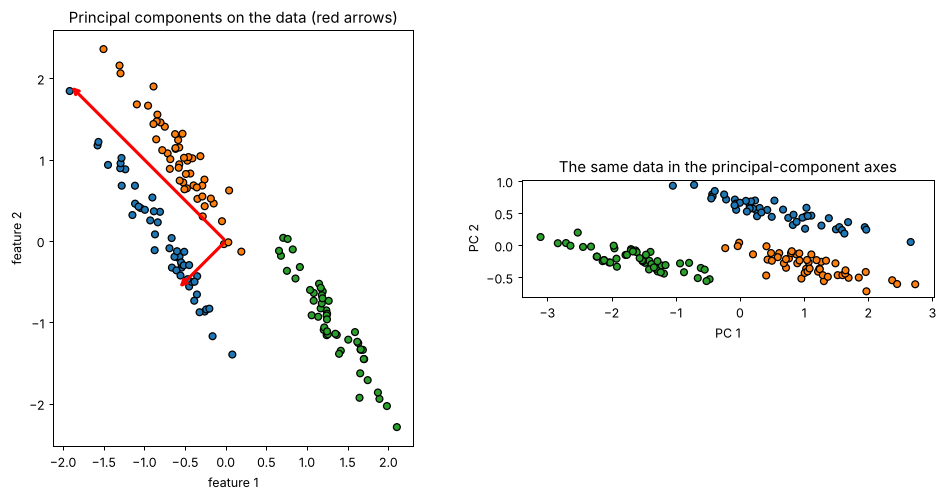

In [16]:
def pca_scratch(X, m):
    Xc = X - X.mean(axis=0)                              # step 1: centre
    cov = Xc.T @ Xc / (len(X) - 1)                       # step 2: covariance matrix
    eigvals, eigvecs = np.linalg.eigh(cov)               # step 3: eigen-decomposition (eigh suits symmetric matrices)
    order = np.argsort(eigvals)[::-1]                    # step 4: largest variance first
    eigvals, eigvecs = eigvals[order], eigvecs[:, order]
    return Xc @ eigvecs[:, :m], eigvals, eigvecs

X, y_true = data['stretched']
Z_scratch, eigvals, eigvecs = pca_scratch(X, 2)
pca = PCA(n_components=2).fit(X)
Z_sklearn = pca.transform(X)

print("Eigenvalues (variance along each component):", np.round(eigvals, 3))
print("Explained variance ratio (scratch):     ", np.round(eigvals / eigvals.sum(), 3))
print("Explained variance ratio (scikit-learn):", np.round(pca.explained_variance_ratio_, 3))
print("Same projection (up to sign):", np.allclose(np.abs(Z_scratch), np.abs(Z_sklearn)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))
ax1.scatter(X[:, 0], X[:, 1], c=y_true % 10, cmap='tab10', vmin=0, vmax=9, s=30, edgecolor='k')
for lam, w in zip(eigvals, eigvecs.T):
    ax1.annotate('', xy=w * np.sqrt(lam) * 2, xytext=(0, 0), arrowprops=dict(arrowstyle='->', lw=2.5, color='r'))
ax1.set(title='Principal components on the data (red arrows)', xlabel='feature 1', ylabel='feature 2')
ax1.set_aspect('equal')
ax2.scatter(Z_scratch[:, 0], Z_scratch[:, 1], c=y_true % 10, cmap='tab10', vmin=0, vmax=9, s=30, edgecolor='k')
ax2.set(title='The same data in the principal-component axes', xlabel='PC 1', ylabel='PC 2')
ax2.set_aspect('equal')
plt.show()


### PCA on real high-dimensional data: handwritten digits
scikit-learn's `load_digits` contains 1,797 images of handwritten digits, each 8 × 8 pixels. Each image is therefore a point in **64 dimensions**, which we cannot plot directly. The true digit labels are used only to check the clustering.


64 features -> 31 components keep 90% of the variance


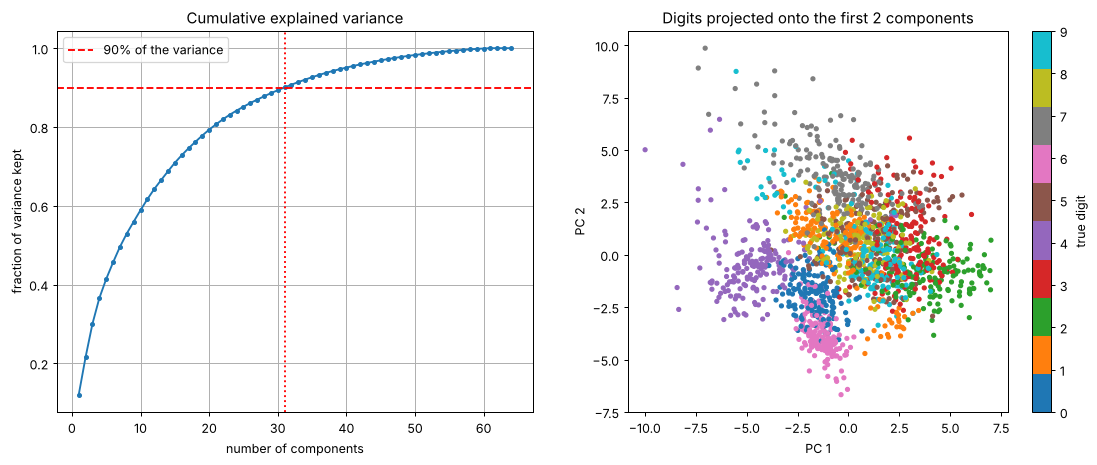

In [17]:
digits = load_digits()
X_dig, y_dig = digits.data, digits.target          # 1797 points, 64 features (pixel intensities)
X_dig_s = StandardScaler().fit_transform(X_dig)    # standardise, since PCA is scale-sensitive

pca_full = PCA().fit(X_dig_s)                      # keep all components to see the variance profile
cum = np.cumsum(pca_full.explained_variance_ratio_)
m90 = int(np.argmax(cum >= 0.90)) + 1              # fewest components that keep 90% of the variance
print(f"{X_dig_s.shape[1]} features -> {m90} components keep 90% of the variance")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
ax1.plot(range(1, len(cum) + 1), cum, 'o-', ms=3)
ax1.axhline(0.9, color='r', ls='--', label='90% of the variance')
ax1.axvline(m90, color='r', ls=':')
ax1.set(title='Cumulative explained variance', xlabel='number of components', ylabel='fraction of variance kept')
ax1.legend()
ax1.grid(True)

Z2 = PCA(n_components=2).fit_transform(X_dig_s)    # 2D view for plotting
sc = ax2.scatter(Z2[:, 0], Z2[:, 1], c=y_dig, cmap='tab10', vmin=0, vmax=9, s=10)
plt.colorbar(sc, ax=ax2, ticks=range(10), label='true digit')
ax2.set(title='Digits projected onto the first 2 components', xlabel='PC 1', ylabel='PC 2')
plt.show()


In [18]:
Z_m = PCA(n_components=m90).fit_transform(X_dig_s)     # reduced data

for name, Xc in [('all 64 features', X_dig_s), (f'{m90} PCA components', Z_m)]:
    km = KMeans(n_clusters=10, n_init=10, random_state=0).fit(Xc)
    print(f"KMeans (k = 10) on {name:<20}: silhouette = {silhouette_score(Xc, km.labels_):.3f}   "
          f"ARI = {adjusted_rand_score(y_dig, km.labels_):.3f}")


KMeans (k = 10) on all 64 features     : silhouette = 0.147   ARI = 0.468
KMeans (k = 10) on 31 PCA components   : silhouette = 0.173   ARI = 0.469


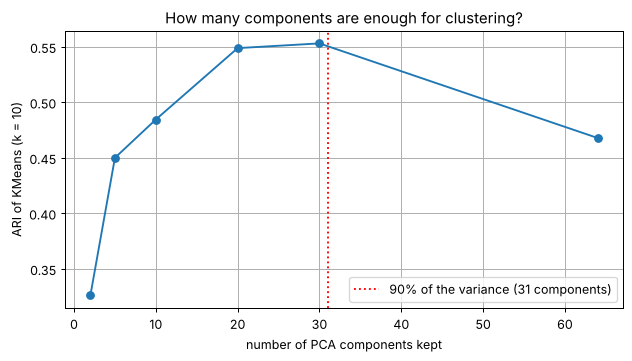

In [19]:
ms = [2, 5, 10, 20, 30, 64]
aris = []
for m in ms:
    Zm = PCA(n_components=m).fit_transform(X_dig_s)
    aris.append(adjusted_rand_score(y_dig, KMeans(n_clusters=10, n_init=10, random_state=0).fit_predict(Zm)))

plt.figure(figsize=(8, 4))
plt.plot(ms, aris, 'o-')
plt.axvline(m90, color='r', ls=':', label=f'90% of the variance ({m90} components)')
plt.xlabel('number of PCA components kept')
plt.ylabel('ARI of KMeans (k = 10)')
plt.title('How many components are enough for clustering?')
plt.legend()
plt.grid(True)
plt.show()


### Things to notice
- Keeping **all 64 components** is just a rotation of the data, so the result is the same as using the raw features (ARI about 0.47).
- Too few components hurt: with 2 components the ARI drops to about 0.33, because the digits are no longer separated well enough.
- A **moderate** number is often best. Around 20 components gives a higher ARI than all 64, because the low-variance directions that are dropped are mostly noise. This is why PCA is worth trying before clustering high-dimensional data.
- Choose $m$ by the explained-variance target **and** by checking a clustering metric such as ARI or silhouette. PCA is unsupervised: the directions with the most variance are not guaranteed to be the ones that separate the clusters.


## 8. All algorithms side by side
Each algorithm runs on each dataset with sensible settings (the true number of clusters, and `eps = 0.35` for DBSCAN).

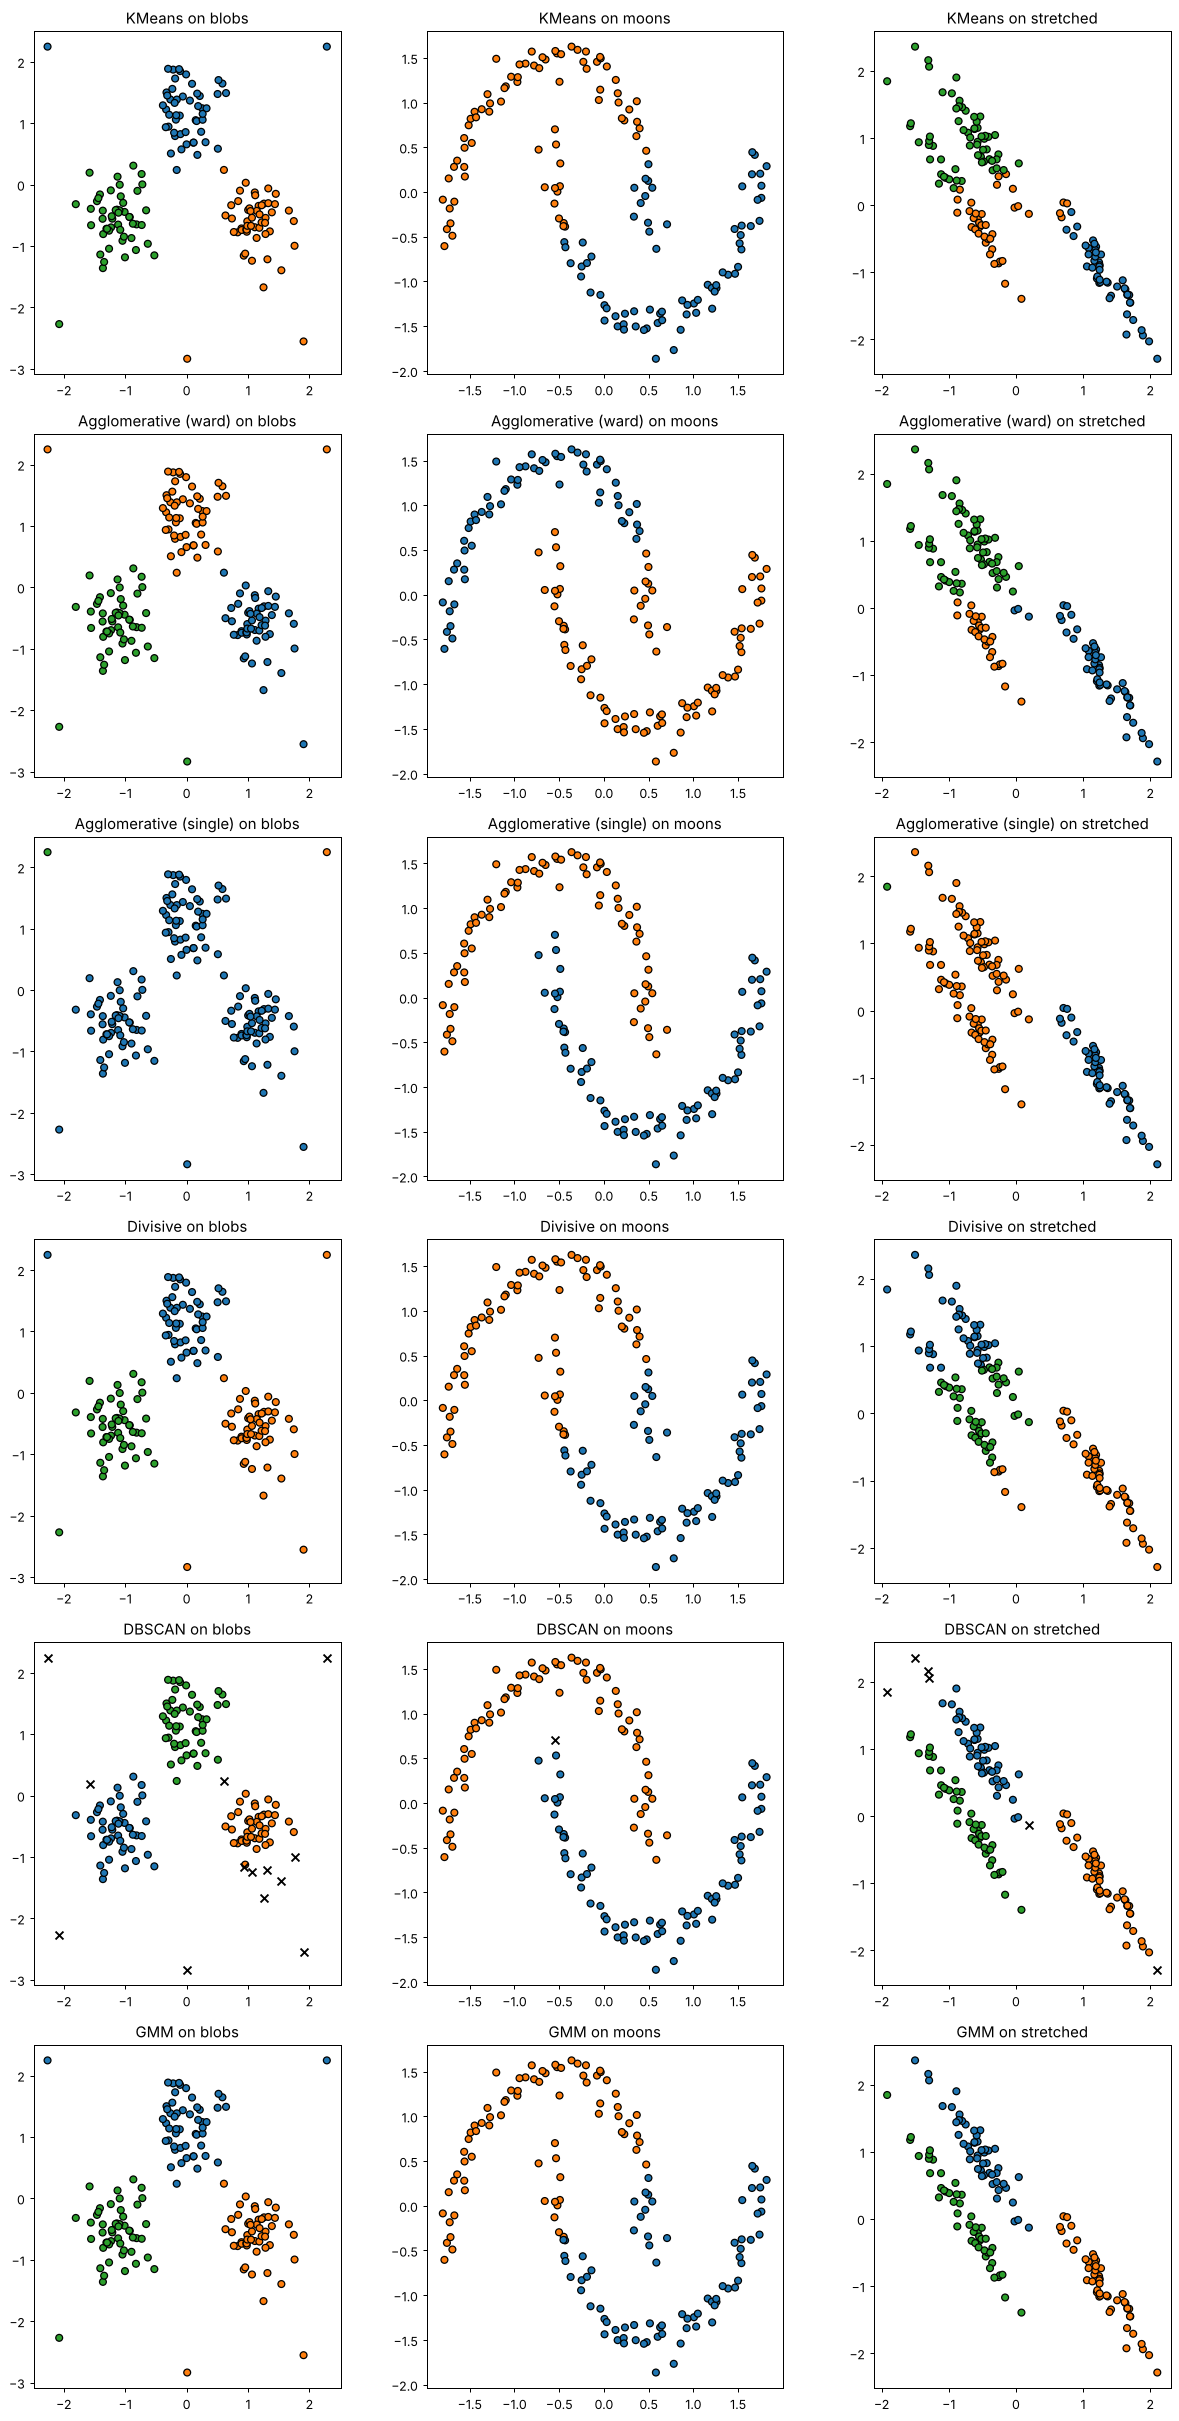

In [20]:
true_k = {'blobs': 3, 'moons': 2, 'stretched': 3}
methods = {
    'KMeans':                 lambda X, k: KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X),
    'Agglomerative (ward)':   lambda X, k: fcluster(linkage(X, 'ward'), k, criterion='maxclust') - 1,
    'Agglomerative (single)': lambda X, k: fcluster(linkage(X, 'single'), k, criterion='maxclust') - 1,
    'Divisive':               lambda X, k: divisive(X, k)[-1],
    'DBSCAN':                 lambda X, k: DBSCAN(eps=0.35, min_samples=5).fit_predict(X),
    'GMM':                    lambda X, k: GaussianMixture(n_components=k, random_state=0).fit_predict(X),
}

fig, axes = plt.subplots(len(methods), 3, figsize=(14, 4.5 * len(methods)))
for row, (name, method) in enumerate(methods.items()):
    for col, (dataset, (X, y_true)) in enumerate(data.items()):
        labels = method(X, true_k[dataset])
        show(X, labels, f'{name} on {dataset}', ax=axes[row, col])
plt.tight_layout()
plt.show()

## 9. Real-dataset use case: customer segmentation
**Customer segmentation.** A shopping mall has data on 200 customers: **annual income** (k$) and **spending score** (1–100, given by the mall based on how much they buy). The goal is to find groups of similar customers so that marketing can treat each group differently.

There are **no labels** here, a truly unsupervised problem, so we judge results with the silhouette score and by looking at the plots. The CSV is downloaded from the web, so this section needs an internet connection.

This section also shows the **scikit-learn class** for each method. They all work the same way: `model = Class(settings)`, then `labels = model.fit_predict(X)`.

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering

mall = pd.read_csv('https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv')
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X_mall = StandardScaler().fit_transform(mall[features])     # scale so both features count equally

# Choosing k with the silhouette score
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X_mall)
    print(f"k = {k}: silhouette = {silhouette_score(X_mall, labels):.3f}")

mall.head()

The silhouette is highest at **k = 5**. Now let's run all four methods. Change `k`, `eps` and `min_samples` and re-run.

In [ ]:
k = 5
eps, min_samples = 0.4, 8     # DBSCAN settings (on the scaled data)

models = {
    'KMeans':               KMeans(n_clusters=k, n_init=10, random_state=0),
    'Agglomerative (ward)': AgglomerativeClustering(n_clusters=k, linkage='ward'),
    'DBSCAN':               DBSCAN(eps=eps, min_samples=min_samples),
    'GMM':                  GaussianMixture(n_components=k, random_state=0),
}

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for ax, (name, model) in zip(axes.ravel(), models.items()):
    labels = model.fit_predict(X_mall)
    keep = labels != -1                                          # DBSCAN noise is left out of the score
    score = silhouette_score(X_mall[keep], labels[keep]) if len(np.unique(labels[keep])) > 1 else float('nan')
    ax.scatter(mall.loc[keep, features[0]], mall.loc[keep, features[1]], c=labels[keep] % 10,
               cmap='tab10', vmin=0, vmax=9, s=40, edgecolor='k')
    ax.scatter(mall.loc[~keep, features[0]], mall.loc[~keep, features[1]], c='k', marker='x', s=50, label='noise')
    ax.set(title=f'{name}   (silhouette = {score:.2f})', xlabel=features[0], ylabel=features[1])
plt.tight_layout()
plt.show()


### What does each segment mean?
Clusters are only useful once we can **describe** them. The average customer of each KMeans segment:

In [ ]:
mall['segment'] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X_mall)
summary = mall.groupby('segment')[features + ['Age']].mean().round(1)
summary['customers'] = mall['segment'].value_counts()
summary

## Summary

### Comparison of the algorithms
| | KMeans | Hierarchical | DBSCAN | GMM |
|---|---|---|---|---|
| **scikit-learn class** | `KMeans` | `AgglomerativeClustering` (bottom-up)<br>`BisectingKMeans` (top-down) | `DBSCAN` | `GaussianMixture` |
| **Type** | hard | hard | hard | **soft** |
| **Concept** | centroid-based | connectivity-based (merge / split) | density-based | model-based (mix of Gaussians) |
| **Hyperparameters** | `k` | `n_clusters` or<br>`distance_threshold`, linkage | `eps`, `min_samples` | no. of Gaussians,<br>covariance type |
| **Cluster shape** | round / convex | depends on linkage<br>(single: any shape) | any shape | ellipses |
| **Outliers** | highly sensitive | sensitive | **robust** (noise) | sensitive |
| **Depends on initialisation?** | yes | no | no | yes |
| **Categorical data** | no (use k-modes) | yes, with a suitable distance | no | no |
| **Cluster a new point?** | yes | no | no | yes |
| **Advantages** | simple, fast | no `k`, dendrogram | no `k`, finds outliers,<br>any shape | probabilistic,<br>ellipse clusters |

**Imports:** `KMeans`, `AgglomerativeClustering`, `BisectingKMeans` and `DBSCAN` come from `sklearn.cluster`, `GaussianMixture` from `sklearn.mixture`. Dendrograms are drawn with `scipy.cluster.hierarchy`. `PCA` comes from `sklearn.decomposition`.

### Applications of clustering
- **Recommendation:** cluster users, then recommend to each user the items that others in their cluster rated well.
- **Customer segmentation** for marketing.
- **Image colour segmentation** (e.g. reducing an image to its k main colours).
- **Video summarisation:** cluster frames into segments and pick key frames.
- **Anomaly detection:** points that fit no cluster (DBSCAN noise, low GMM probability).
- Scientific data, e.g. classifying treated wastewater or comparing RADAR signals.